# Overnight sweep — mini-batch training, LR schedules, architectures (2026-10-06/07)

**Task:** lowest test MSE on the **80/20 chronological split** (train days 0–111.4, test days 111.4–139.7),
`n·*` features only (8 look-direction dot products). 49 training runs, ~6.5 h on 2 parallel CPU lanes.
Code: `sweeps/mb_train.jl`, configs: `sweeps/configs.jl`, raw results: `sweeps/results/*.jls`,
full table: `sweeps/results/summary.txt`.

## Headline

| model | test MSE | test rms (MJy/sr) | frac. error | wall time |
|---|---|---|---|---|
| full-batch 64-64-32-16, 2000 ep (yesterday) | 9.3e-4 | 0.030 | 6.5% | ~2 h |
| mini-batch 64-64-32-16, one-cycle 1e-3, 100 ep (7-seed mean) | 1.55e-4 | 0.012 | 2.6% | 6 min |
| **ensemble of 7 seeds of the above** | **9.5e-5** | **0.0097** | **2.1%** | 7 × 6 min |
| ensemble of 5 seeds (the notebook recipe) | 9.4e-5 | 0.0097 | 2.0% | 5 × 6 min |

**Recommended recipe:** 64-64-32-16 gelu MLP, batch 512, Adam, one-cycle LR (peak 1e-3), 100 epochs,
average 5+ seeds. ~10× lower test MSE than full-batch, in a fraction of the time.

## Findings

1. **Mini-batching is the big win.** Batch 512 reaches the full-batch 2-hour result in ~2 epochs (~5 s).
2. **The bottleneck is now extrapolation, not fitting.** Train MSE reaches 1e-6–1e-7, test plateaus at
   ~1–2e-4 by epoch ~20. Extra training/capacity improves the fit to days 0–111 without improving days 111–140.
3. **Seed noise ≈ 2× (up to 13× for big nets) — larger than schedule differences.** Never rank configs from one seed.
4. **Schedules (64-64-32-16, 3 seeds each, test MSE mean):** linear 1e-3 → 1.4e-4, one-cycle 1e-3 → 1.6e-4,
   cos×exp 3e-3 → 2.0e-4. Statistically indistinguishable. **Peak LR 1e-2 is unsafe**: one-cycle 1e-2 → 1.4e-3,
   cos×exp 1e-2 had one seed at 6.0e-3 (56× worse).
5. **Bigger is worse here.** Test MSE (seed mean): 32-16 → 6.9e-4 (underfits), **64-64-32-16 → 1.6e-4 (best)**,
   128-128-64-32 → 2.9e-4, 128×4-64-32 → 2.8e-4, 256-256-128-64 → 8.8e-4. Bigger nets fit training better
   but extrapolate worse and less consistently.
6. **ResMLPs:** best single run of the night (w128×4, seed 42: 6.8e-5) but its other seed was 8.7e-4.
   w64×3: 4-seed mean 4.1e-4, yet its 4-seed **ensemble 1.05e-4** — residual nets are high-variance;
   ensembling rescues them but doesn't beat the plain 64-64-32-16 ensemble. w256×4: 1.6e-3.
7. **Ensembling helps every config** (typ. 30–75% lower MSE than the seed mean) because seeds extrapolate differently.
8. **What's left:** test residuals drift steadily negative after the boundary (≈ −0.02 MJy/sr by day 140) and are
   largest near the ecliptic poles and at elongation 85–90°. The drift is shared by all seeds (ensembling doesn't
   remove it) → it's missing information (orbital phase vs. the tilted cloud), not noise.

## Caveat

Configs were compared on the test set itself (there is no separate validation period), so the very best
numbers are mildly optimistic. The recommendation relies on seed means and ensembles, not on the single luckiest run.

## Suggested next steps

1. Carve a **validation period** (e.g. days 100–111) out of training for model selection / early stopping.
2. **Weight decay / smaller LR late** — the train/test gap is now ~40×; mild regularization may help extrapolation.
3. Attack the drift with **non-clock Earth-anchored features** (`n·δ`, onboarding Earth-centric section) or by testing on
   splits where orbital phase is covered (30-day blocks), to separate "missing physics" from "unseen season".
4. **Positive output / log target** (onboarding stretch goal 4–5) to target fractional error at the poles.


In [2]:
# ==============================================================================
# ZODI SETUP — environment, data, feature helpers, train/test splits
# Copy this whole cell into any notebook (or `include` this file).
# ==============================================================================

# --- Environment -------------------------------------------------------------
# Use the notebook's own folder if it has a data/ directory, otherwise fall back
# to the main More_zodi project so this cell works from any notebook.
PROJECT_DIR = isdir(joinpath(@__DIR__, "..", "data")) ? (joinpath(@__DIR__, "..")) : raw"C:\JuliaProjects\More_zodi"

import Pkg
Pkg.activate(PROJECT_DIR)
let needed = ["HDF5", "StatsBase", "CairoMakie", "NaNStatistics", "ProgressMeter", "ColorSchemes"]
    missing_pkgs = setdiff(needed, keys(Pkg.project().dependencies))
    isempty(missing_pkgs) || Pkg.add(missing_pkgs)
end
try
    Pkg.instantiate()
catch err   # e.g. "X is a direct dependency, but does not appear in the manifest"
    @warn "Pkg.instantiate failed — running Pkg.resolve() and retrying" exception = err
    Pkg.resolve()
    Pkg.instantiate()
end

using HDF5, StatsBase, Statistics, Random, CairoMakie, Printf
using NaNStatistics, ProgressMeter, ColorSchemes
black_latexfonts = merge(theme_black(), theme_latexfonts())
set_theme!(black_latexfonts)
CairoMakie.disable_mime!("svg", "pdf", "text/html")

# --- Data files --------------------------------------------------------------
DATA_DIR = joinpath(PROJECT_DIR, "data")

pointing_file = joinpath(DATA_DIR, "boresight_pointing.h5")
vectors_file  = joinpath(DATA_DIR, "spherex_vectors_bore_interpolated.h5")
allsky_file   = joinpath(DATA_DIR, "spherex_zodipy_5um_boresight_healpix_components_interpolated.h5")
emission_file = joinpath(DATA_DIR, "spherex_zodipy_5um_boresight_interpolated.h5")

# Where is SPHEREx looking?
nvec_unit_cartesian, ecliptic_longitude_deg, ecliptic_latitude_deg, times = h5open(pointing_file) do f
    read(f["pointing/nvec_unit_cartesian"]),     # 3 × N
    read(f["pointing/ecliptic_longitude_deg"]),
    read(f["pointing/ecliptic_latitude_deg"]),
    read(f["times/julian_date"])                 # Julian Date (days); NOT sorted
end

earth_positions, v_earth, jupiter_positions, spherex_positions, v_spherex, moon_positions =
    h5open(vectors_file) do f
        read(f["earth/positions"]),   read(f["earth/velocities"]),
        read(f["jupiter/positions"]),
        read(f["spherex/positions"]), read(f["spherex/velocities"]),
        read(f["moon/positions"])
    end

zhat_vec = zero(earth_positions); zhat_vec[3, :] .= 1.0
xhat_vec = zero(earth_positions); xhat_vec[1, :] .= 1.0
yhat_vec = zero(earth_positions); yhat_vec[2, :] .= 1.0

v_earth_unit   = v_earth   ./ sqrt.(sum(v_earth .^ 2, dims=1))
v_spherex_unit = v_spherex ./ sqrt.(sum(v_spherex .^ 2, dims=1))

# --- The target: Kelsall-model 5 μm emission along each boresight ---
y = h5open(emission_file) do f
    meta = attrs(f["metadata"])
    println("description: ", meta["description"])
    println("wavelength:  ", meta["wavelength"], " ", meta["wavelength_units"])
    println("units:       ", meta["emission_units"])
    read(f["emission"])            # MJy/sr, length N
end
N = length(y)
@assert size(nvec_unit_cartesian, 2) == size(spherex_positions, 2) == length(times) == N
println("N = $N exposures;  emission range = ", extrema(y))

# --- Feature helpers ---------------------------------------------------------
dot_prod_matrix(a, b) = dropdims(sum(a .* b, dims=1), dims=1)

# make_vectors(nvec, idx) — THE one place the model inputs are defined.
#   `nvec`: 3 × M pointing directions.  `idx`: indices into the per-exposure ephemeris
#   columns — use 1:N for the boresight data, or fill(t, M) to evaluate everything at
#   a single epoch t (used for the all-sky map at the end).
# Add a vector here and every model and validation downstream sees it automatically.
make_vectors(nvec, idx) = [
    "n"  => nvec,
    "S"  => spherex_positions[:, idx],
    "z"  => zhat_vec[:, idx],
    "E"  => earth_positions[:, idx],
    "vS" => v_spherex_unit[:, idx],
    "vE" => v_earth_unit[:, idx],
    "J"  => jupiter_positions[:, idx],
    "x"  => xhat_vec[:, idx],        # fixed in-plane inertial axes
    "y"  => yhat_vec[:, idx],
]

# all pairwise dot products among the registered vectors
function dot_features(vecs)
    names, cols = String[], Vector{Float64}[]
    for i in eachindex(vecs), j in i:length(vecs)
        push!(names, string(first(vecs[i]), "·", first(vecs[j])))
        push!(cols, dot_prod_matrix(last(vecs[i]), last(vecs[j])))
    end
    return names, reduce(hcat, cols)
end

# all squares and pairwise products of (already standardized) features —
# the hand-made curvature for the linear-plus-quadratic model
function quadratic_terms(names, D)
    qnames, qcols = String[], Vector{Float64}[]
    for i in axes(D, 2), j in i:size(D, 2)
        push!(qnames, i == j ? "($(names[i]))²" : "($(names[i]))($(names[j]))")
        push!(qcols, D[:, i] .* D[:, j])
    end
    return qnames, reduce(hcat, qcols)
end

# a first look at the raw dot products and their spread
dot_names_all, Fd_raw = dot_features(make_vectors(nvec_unit_cartesian, 1:N))
for (nm, i) in zip(dot_names_all, axes(Fd_raw, 2))
    @printf("%-6s  median %10.3e   iqr %10.3e\n", nm, median(Fd_raw[:, i]), iqr(Fd_raw[:, i]))
end

# --- Train/test splits (all chronological except the random one) ------------
# The rows are NOT in time order and times[1] is not the earliest exposure, so
# time_days (same convention as the file's times/days_since_start) runs from
# about -6.2 to +133.5. Splits use t_rel, measured from the first exposure.
time_days = times .- times[1]
t_rel     = time_days .- minimum(time_days)    # 0 → ~139.7 days
c_idx     = sortperm(time_days)                # row indices in chronological order
span_days = maximum(t_rel)

chrono_split(frac) = (k = floor(Int, frac * N); (c_idx[1:k], c_idx[k+1:N]))

# alternate fixed-length time windows train/test/train/... (by actual days, not row count)
function alternating_time_split(window_days)
    blk = floor.(Int, t_rel ./ window_days)    # 0, 1, 2, ... → train, test, train, ...
    (findall(iseven, blk), findall(isodd, blk))
end

rng = Xoshiro(2026)
train_idx_rnm = sort(sample(rng, 1:N, N ÷ 2, replace=false))
test_idx_rnm  = setdiff(1:N, train_idx_rnm)

# middle 50% of exposures (chronologically) held out, outer 50% trained on
p1, p2 = floor(Int, 0.25N), floor(Int, 0.75N)
train_idx_mid = vcat(c_idx[1:p1], c_idx[p2+1:N])
test_idx_mid  = c_idx[p1+1:p2]

splits = Dict(
    "75/25 Chronological" => chrono_split(0.75),
    "50/50 Chronological" => chrono_split(0.50),
    "25/75 Chronological" => chrono_split(0.25),
    "80/20 Chronological" => chrono_split(0.80),
    "85/15 Chronological" => chrono_split(0.85),
    "random split"        => (train_idx_rnm, test_idx_rnm),
    "30 day split"        => alternating_time_split(30.0),
    "7-day alternating"   => alternating_time_split(7.0),
    "50/50 mid-mission"   => (train_idx_mid, test_idx_mid),
)

@printf("\nMission span: %.1f days\n", span_days)
for name in sort(collect(keys(splits)))
    tr, te = splits[name]
    @assert isempty(intersect(tr, te)) && length(tr) + length(te) == N
    @printf("%-20s train %7d   test %7d   (%.0f%% train)\n", name, length(tr), length(te), 100length(tr) / N)
end
println("All splits initialized.")

  Activating project at `c:\JuliaProjects\More_zodi`


description: Zodiacal light predictions for SPHEREx pointing directions
wavelength:  5.0 micron
units:       MJy/sr
N = 423607 exposures;  emission range = (0.31956938511238003, 1.0941130974339088)
n·n     median  1.000e+00   iqr  0.000e+00
n·S     median  4.851e-03   iqr  3.475e-01
n·z     median  9.747e-03   iqr  1.361e+00
n·E     median  4.805e-03   iqr  3.475e-01
n·vS    median  1.615e-02   iqr  1.356e+00
n·vE    median  3.680e-02   iqr  1.383e+00
n·J     median -5.953e-02   iqr  2.659e+00
n·x     median  5.145e-02   iqr  8.549e-01
n·y     median -1.072e-03   iqr  5.523e-01
S·S     median  1.037e+00   iqr  1.341e-02
S·z     median  2.050e-04   iqr  6.195e-05
S·E     median  1.037e+00   iqr  1.341e-02
S·vS    median -1.048e-02   iqr  5.980e-02
S·vE    median -5.250e-03   iqr  2.289e-02
S·J     median -4.519e+00   iqr  1.400e+00
S·x     median  2.056e-01   iqr  1.095e+00
S·y     median -8.518e-01   iqr  3.210e-01
z·z     median  1.000e+00   iqr  0.000e+00
z·E     median  2.096e-04   

Solar elongation over all exposures: 85.2° – 129.7° (median 90.3°)
Sky observed at least once: 82.0% of 3072 pixels
Pixels seen at < 5° elongation spread: 37.0% of observed sky


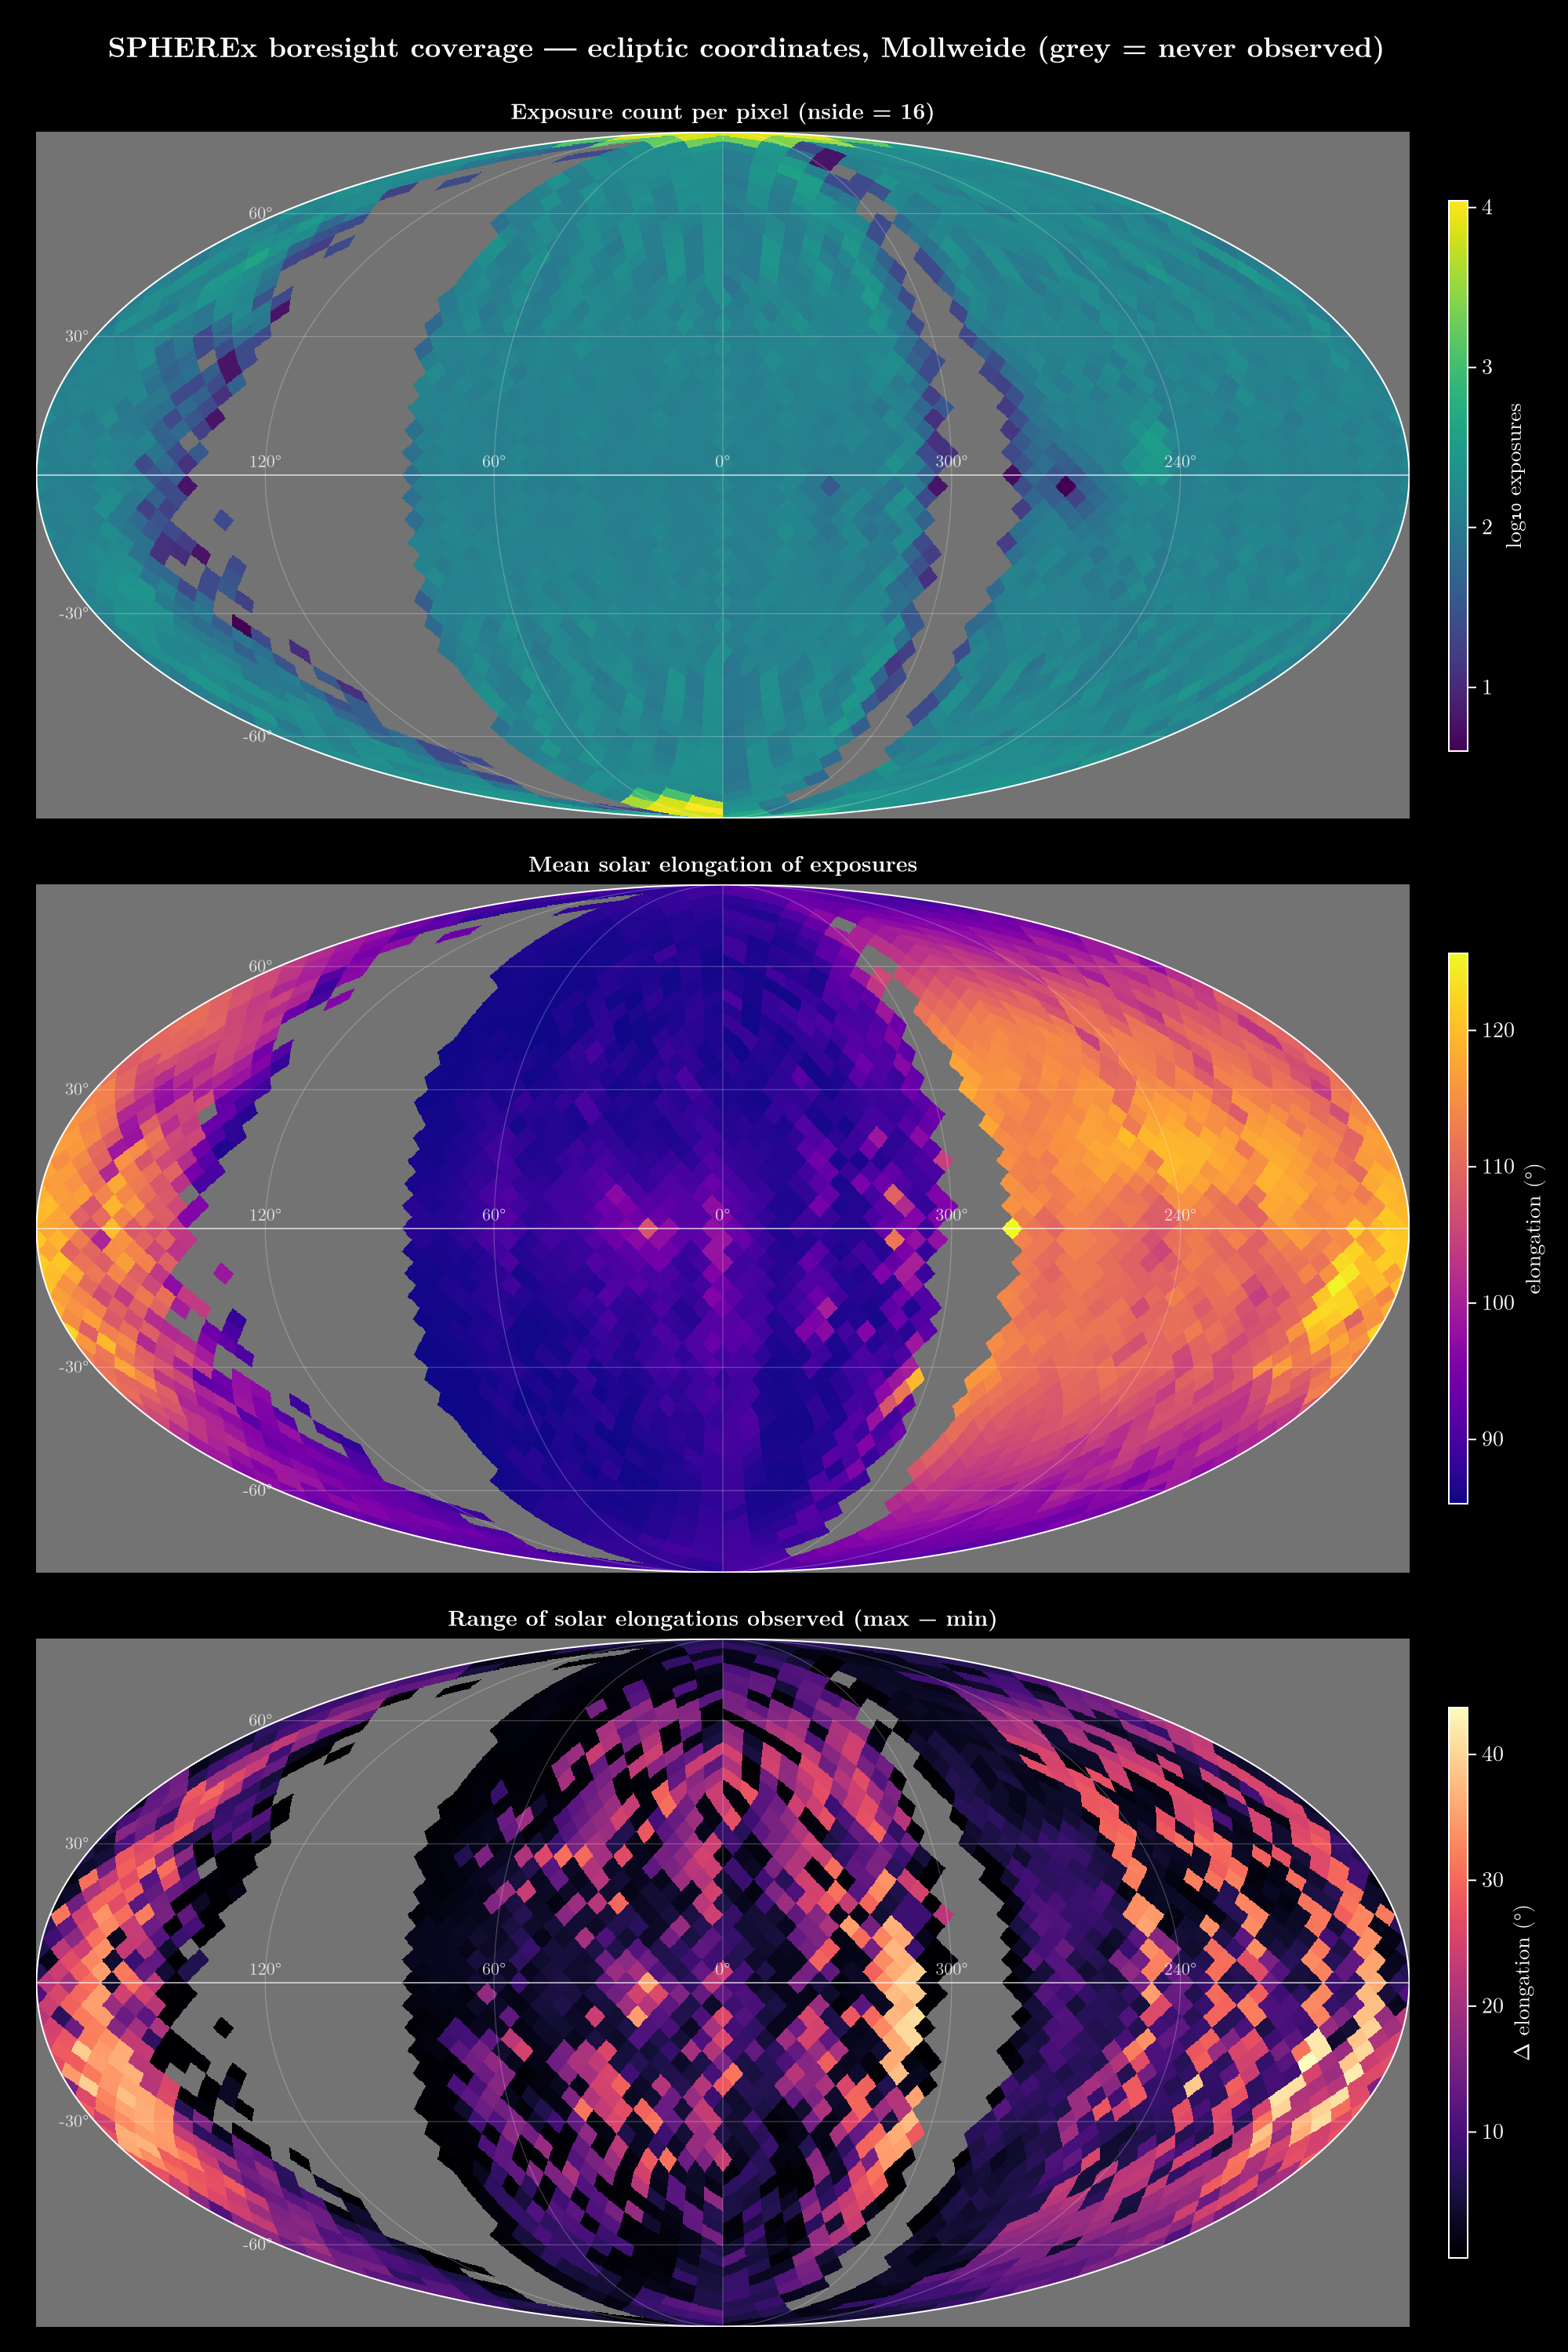

In [3]:
# ==============================================================================
# SOLAR ELONGATION SKY COVERAGE — Mollweide maps in ecliptic coordinates
# Requires the ZODI SETUP cell above.
#
# Every exposure is binned into a HEALPix pixel (by boresight direction) and we map
#   1. how many exposures landed in each pixel,
#   2. the mean solar elongation they were taken at,
#   3. the spread (max − min) of elongations seen in each pixel.
# Grey = never observed. Small spread = that patch of sky was only ever seen at
# one Sun angle, so the model has little information about how zodi changes there.
# ==============================================================================
using Healpix

# Pixel size: these are boresight points only, and neighbouring scan lines are more
# than 1° apart, so finer pixels show false "gaps" between scans. nside 16 (3.7°)
# is about one SPHEREx exposure footprint (~3.5°). Sky observed: 82% at nside 16,
# 64% at 32, 32% at 64.
ELONG_NSIDE = 16          # 3,072 pixels, ~3.7° across

# --- Solar elongation of every exposure --------------------------------------
# Positions are barycentric; we take the Sun ≈ barycenter, so the Sun direction
# from SPHEREx is −Ŝ. (Sun–barycenter offset ≲ 0.01 AU → ≲ 0.6° error.)
# Note: the data spans 85.2°–129.7°, i.e. below the nominal 91° avoidance limit.
S_unit          = spherex_positions ./ sqrt.(sum(spherex_positions .^ 2, dims=1))
solar_elong_deg = acosd.(clamp.(-dot_prod_matrix(nvec_unit_cartesian, S_unit), -1.0, 1.0))
@printf("Solar elongation over all exposures: %.1f° – %.1f° (median %.1f°)\n",
        extrema(solar_elong_deg)..., median(solar_elong_deg))

# --- Bin exposures into HEALPix pixels (ecliptic frame) ----------------------
elong_res = Healpix.Resolution(ELONG_NSIDE)
npix      = Healpix.nside2npix(ELONG_NSIDE)
pix_count = zeros(Int, npix)
pix_sum   = zeros(npix)
pix_min   = fill(Inf, npix)
pix_max   = fill(-Inf, npix)
for i in 1:N
    nx, ny, nz = nvec_unit_cartesian[1, i], nvec_unit_cartesian[2, i], nvec_unit_cartesian[3, i]
    p = Healpix.ang2pixRing(elong_res, acos(clamp(nz, -1.0, 1.0)), mod(atan(ny, nx), 2π))
    e = solar_elong_deg[i]
    pix_count[p] += 1
    pix_sum[p]   += e
    pix_min[p]    = min(pix_min[p], e)
    pix_max[p]    = max(pix_max[p], e)
end
seen       = pix_count .> 0
pix_mean   = ifelse.(seen, pix_sum ./ max.(pix_count, 1), NaN)
pix_spread = ifelse.(seen, pix_max .- pix_min, NaN)
pix_logn   = ifelse.(seen, log10.(max.(pix_count, 1)), NaN)
@printf("Sky observed at least once: %.1f%% of %d pixels\n", 100mean(seen), npix)
@printf("Pixels seen at < 5° elongation spread: %.1f%% of observed sky\n",
        100mean(pix_spread[seen] .< 5))

# --- Mollweide projection ----------------------------------------------------
# Ecliptic longitude 0° at the centre, increasing to the LEFT (sky-view convention).
function mollweide(lon_deg, lat_deg)
    λ = deg2rad(mod(lon_deg + 180, 360) - 180)
    φ = deg2rad(lat_deg)
    θ = φ
    if abs(φ) < π/2 - 1e-9            # Newton solve of 2θ + sin 2θ = π sin φ
        for _ in 1:50
            Δ = (2θ + sin(2θ) - π * sin(φ)) / (2 + 2cos(2θ))
            θ -= Δ
            abs(Δ) < 1e-12 && break
        end
    end
    return (-2√2 / π * λ * cos(θ), √2 * sin(θ))
end

# (x, y) on the Mollweide plane → (lon, lat) in degrees; NaN outside the ellipse
function inv_mollweide(x, y)
    abs(y) > √2 && return (NaN, NaN)
    θ   = asin(y / √2)
    lon = -rad2deg(π * x / (2√2 * cos(θ)))
    abs(lon) > 180 && return (NaN, NaN)
    return (lon, asind(clamp((2θ + sin(2θ)) / π, -1.0, 1.0)))
end

# rasterise a HEALPix-ordered vector onto the Mollweide plane
function mollweide_raster(vals; nx=1600, ny=800)
    xs  = range(-2√2, 2√2, length=nx)
    ys  = range(-√2, √2, length=ny)
    img = fill(NaN, nx, ny)
    for (j, yv) in enumerate(ys), (i, xv) in enumerate(xs)
        lon, lat = inv_mollweide(xv, yv)
        isnan(lon) && continue
        p = Healpix.ang2pixRing(elong_res, deg2rad(90 - lat), deg2rad(mod(lon, 360)))
        img[i, j] = vals[p]
    end
    return xs, ys, img
end

# graticule: parallels every 30°, meridians every 60°, plus the outline
function draw_graticule!(ax)
    for lat in -60:30:60
        pts = [Point2f(mollweide(lon, lat)...) for lon in range(-179.999, 179.999, length=361)]
        lines!(ax, pts, color=(:white, lat == 0 ? 0.6 : 0.25), linewidth=lat == 0 ? 1.0 : 0.6)
    end
    for lon in -120:60:180
        pts = [Point2f(mollweide(lon == 180 ? 179.999 : lon, lat)...) for lat in -90:0.5:90]
        lines!(ax, pts, color=(:white, 0.25), linewidth=0.6)
    end
    for lon in (-179.999, 179.999)    # outline
        lines!(ax, [Point2f(mollweide(lon, lat)...) for lat in -90:0.5:90], color=:white, linewidth=1)
    end
    for lon in -120:60:120             # longitude labels along the ecliptic
        text!(ax, Point2f(mollweide(lon, 0)...), text="$(mod(lon, 360))°",
              fontsize=11, color=(:white, 0.8), align=(:center, :bottom), offset=(0, 3))
    end
    for lat in (-60, -30, 30, 60)      # latitude labels at the left edge
        text!(ax, Point2f(mollweide(179.999, lat)...), text="$(lat)°",
              fontsize=11, color=(:white, 0.8), align=(:right, :center), offset=(-4, 0))
    end
end

function mollweide_panel!(fig, row, vals, title, cmap, label; colorrange=nothing)
    ax = Axis(fig[row, 1], title=title, aspect=DataAspect())
    hidedecorations!(ax); hidespines!(ax)
    xs, ys, img = mollweide_raster(vals)
    cr = colorrange === nothing ? extrema(filter(!isnan, img)) : colorrange
    hm = heatmap!(ax, xs, ys, img, colormap=cmap, colorrange=cr, nan_color=(:grey45, 1.0))
    draw_graticule!(ax)
    Colorbar(fig[row, 2], hm, label=label, height=Relative(0.8))
    return ax
end

fig_elong = Figure(size=(1000, 1500))
mollweide_panel!(fig_elong, 1, pix_logn,   "Exposure count per pixel (nside = $ELONG_NSIDE)",
                 :viridis, "log₁₀ exposures")
mollweide_panel!(fig_elong, 2, pix_mean,   "Mean solar elongation of exposures",
                 :plasma, "elongation (°)")
mollweide_panel!(fig_elong, 3, pix_spread, "Range of solar elongations observed (max − min)",
                 :magma, "Δ elongation (°)")
Label(fig_elong[0, :], "SPHEREx boresight coverage — ecliptic coordinates, Mollweide (grey = never observed)",
      fontsize=18, font=:bold)
save(joinpath(PROJECT_DIR, "figures", "solar_elongation_mollweide.png"), fig_elong)
fig_elong

In [ ]:
# ==============================================================================
# SMALL MLP  (n_features → 32 → 16 → 1)  ON THE 80/20 CHRONOLOGICAL SPLIT
# Requires the ZODI SETUP cell. Full-batch Adam, MSE loss, linear LR schedule.
# ~0.7 s/epoch on CPU → ~9 min for 750 epochs.
# ==============================================================================
using Flux

split_name     = "80/20 Chronological"
tr_idx, te_idx = splits[split_name]

epochs     = 750
lr_initial = 1e-3     # learning rate at epoch 1
lr_final   = 1e-4     # learning rate at the last epoch (set = lr_initial for a constant rate)
lr_schedule(epoch) = lr_initial + (lr_final - lr_initial) * (epoch - 1) / max(epochs - 1, 1)
lr_hist = lr_schedule.(1:epochs)

# --- A. Normalization from TRAINING rows only (split before normalizing) -----
keep_dots = [iqr(Fd_raw[tr_idx, i]) > 1e-12 for i in axes(Fd_raw, 2)]
dot_names = dot_names_all[keep_dots]
dot_mean  = [median(Fd_raw[tr_idx, i]) for i in axes(Fd_raw, 2)][keep_dots]
dot_norm  = [iqr(Fd_raw[tr_idx, i]) / 1.34896 for i in axes(Fd_raw, 2)][keep_dots]
standardize_dots(Fd) = (Fd[:, keep_dots] .- dot_mean') ./ dot_norm'

D_tr = standardize_dots(Fd_raw[tr_idx, :])
D_te = standardize_dots(Fd_raw[te_idx, :])

# --- B. Reference baselines (dashed lines on the loss plot) -----------------
mse_null = mean(abs2, y[te_idx] .- mean(y[tr_idx]))
c_lin    = hcat(ones(length(tr_idx)), D_tr) \ y[tr_idx]
mse_lin  = mean(abs2, y[te_idx] .- hcat(ones(length(te_idx)), D_te) * c_lin)

# --- C. Flux inputs: (n_features × n_samples), Float32 ----------------------
Xtr = Float32.(D_tr')
Xte = Float32.(D_te')
Ytr = Float32.(reshape(y[tr_idx], 1, :))
Yte = Float32.(reshape(y[te_idx], 1, :))
n_in = size(Xtr, 1)
println("$split_name: $(size(Xtr, 2)) train / $(size(Xte, 2)) test, $n_in features")

rng = Random.Xoshiro(42)
model_small = Chain(
    Dense(n_in => 32, gelu; init=Flux.glorot_uniform(rng)),
    Dense(32 => 16, gelu;   init=Flux.glorot_uniform(rng)),
    Dense(16 => 1;          init=Flux.glorot_uniform(rng)),
)
println("parameters: ", sum(length, Flux.trainables(model_small)))

opt_state = Flux.setup(Adam(lr_initial), model_small)
loss_fn(m, x, y_true) = Flux.mse(m(x), y_true)

tr_loss_hist = Float64[loss_fn(model_small, Xtr, Ytr)]
te_loss_hist = Float64[loss_fn(model_small, Xte, Yte)]

# --- D. Training loop --------------------------------------------------------
println("Training for $epochs epochs (linear lr $lr_initial → $lr_final)...")
t_start = time()
for epoch in 1:epochs
    Flux.adjust!(opt_state, lr_hist[epoch])
    grads = Flux.gradient(m -> loss_fn(m, Xtr, Ytr), model_small)
    Flux.update!(opt_state, model_small, grads[1])

    push!(tr_loss_hist, loss_fn(model_small, Xtr, Ytr))
    push!(te_loss_hist, loss_fn(model_small, Xte, Yte))

    if epoch % 50 == 0 || epoch == 1
        @printf("  Epoch %4d/%d - lr: %.2e | Train: %.6e | Test: %.6e | %.0fs\n",
                epoch, epochs, lr_hist[epoch], tr_loss_hist[end], te_loss_hist[end], time() - t_start)
    end
end

@printf("\n  test MSE   null: %.5e   linear: %.5e\n", mse_null, mse_lin)
@printf("  NN MSE     train: %.5e | test: %.5e\n", tr_loss_hist[end], te_loss_hist[end])
@printf("  NN test rms: %.4f MJy/sr (%.2f%% of median emission)\n",
        sqrt(te_loss_hist[end]), 100sqrt(te_loss_hist[end]) / median(y))

# --- E. Loss curves ----------------------------------------------------------
fig_small = Figure(size=(900, 750), fontsize=14)
ax_lr = Axis(fig_small[1, 1], ylabel="Learning rate",
             title="$n_in → 32 → 16 → 1 MLP, $split_name split")
lines!(ax_lr, 1:epochs, lr_hist, color=:white, linewidth=2)

ax_loss = Axis(fig_small[2, 1], xlabel="Epoch", ylabel="MSE loss (MJy/sr)²", yscale=log10)
lines!(ax_loss, 0:epochs, tr_loss_hist, label="Train", color=:dodgerblue, linewidth=2)
lines!(ax_loss, 0:epochs, te_loss_hist, label="Test",  color=:orangered,  linewidth=2)
hlines!(ax_loss, [mse_null], color=:gray70, linestyle=:dash, label="Null (train mean)")
hlines!(ax_loss, [mse_lin],  color=:gold,   linestyle=:dash, label="Linear on dots")
axislegend(ax_loss, position=:rt)

linkxaxes!(ax_lr, ax_loss)
hidexdecorations!(ax_lr, grid=false)
rowsize!(fig_small.layout, 1, Relative(0.25))
save(joinpath(PROJECT_DIR, "figures", "small_mlp_80_20_loss.png"), fig_small)
fig_small

In [ ]:
# ==============================================================================
# train_mlp — the small-MLP training above, as a function of FEATURE SET and WIDTHS
# Requires the ZODI SETUP cell. Same recipe: robust standardization from training
# rows only, full-batch Adam, MSE loss, linear LR schedule, gelu hidden layers.
# `hidden` = hidden-layer widths, e.g. (32, 16) → n_in → 32 → 16 → 1.
# Returns a NamedTuple with the model, loss histories, baselines and predictions.
# ==============================================================================
using Flux

function train_mlp(feature_names; hidden=(32, 16), split_name="80/20 Chronological", epochs=750,
                   lr_initial=1e-3, lr_final=1e-4, seed=42, print_every=50)
    tr_idx, te_idx = splits[split_name]
    cols = [findfirst(==(nm), dot_names_all) for nm in feature_names]
    any(isnothing, cols) && error("unknown feature(s): ", feature_names[isnothing.(cols)])

    # --- standardization constants from TRAINING rows only -------------------
    F  = Fd_raw[:, cols]
    μ  = [median(F[tr_idx, j]) for j in axes(F, 2)]
    σ  = [iqr(F[tr_idx, j]) / 1.34896 for j in axes(F, 2)]
    any(σ .< 1e-12) && error("feature(s) constant on training rows: ", feature_names[σ .< 1e-12])
    D  = (F .- μ') ./ σ'

    # --- baselines on the same features and split ----------------------------
    mse_null = mean(abs2, y[te_idx] .- mean(y[tr_idx]))
    A        = hcat(ones(N), D)
    c_lin    = A[tr_idx, :] \ y[tr_idx]
    mse_lin  = mean(abs2, y[te_idx] .- (A * c_lin)[te_idx])

    # --- Flux data: (n_features × n_samples), Float32 -------------------------
    X   = Float32.(D')
    Xtr, Xte = X[:, tr_idx], X[:, te_idx]
    Ytr = Float32.(reshape(y[tr_idx], 1, :))
    Yte = Float32.(reshape(y[te_idx], 1, :))
    n_in = size(X, 1)

    rng    = Random.Xoshiro(seed)
    widths = (n_in, hidden...)
    model  = Chain(
        [Dense(widths[i] => widths[i+1], gelu; init=Flux.glorot_uniform(rng)) for i in 1:length(hidden)]...,
        Dense(widths[end] => 1; init=Flux.glorot_uniform(rng)),
    )
    n_params = sum(length, Flux.trainables(model))
    lr_hist   = [lr_initial + (lr_final - lr_initial) * (e - 1) / max(epochs - 1, 1) for e in 1:epochs]
    opt_state = Flux.setup(Adam(lr_initial), model)
    loss_fn(m, x, yt) = Flux.mse(m(x), yt)

    tr_hist = Float64[loss_fn(model, Xtr, Ytr)]
    te_hist = Float64[loss_fn(model, Xte, Yte)]
    println("$(join(widths, " → ")) → 1 ($n_params params), $split_name, $epochs epochs (lr $lr_initial → $lr_final)")
    t0 = time()
    for epoch in 1:epochs
        Flux.adjust!(opt_state, lr_hist[epoch])
        grads = Flux.gradient(m -> loss_fn(m, Xtr, Ytr), model)
        Flux.update!(opt_state, model, grads[1])
        push!(tr_hist, loss_fn(model, Xtr, Ytr))
        push!(te_hist, loss_fn(model, Xte, Yte))
        if epoch % print_every == 0 || epoch == 1
            @printf("  Epoch %4d/%d - lr: %.2e | Train: %.6e | Test: %.6e | %.0fs\n",
                    epoch, epochs, lr_hist[epoch], tr_hist[end], te_hist[end], time() - t0)
        end
    end
    @printf("  test MSE  null %.3e | linear %.3e | NN %.3e (train %.3e)\n",
            mse_null, mse_lin, te_hist[end], tr_hist[end])

    ypred = Float64.(vec(model(X)))          # predictions for ALL exposures
    return (; feature_names, hidden, n_params, split_name, tr_idx, te_idx, μ, σ, model, lr_hist,
              tr_hist, te_hist, mse_null, mse_lin, ypred)
end

In [ ]:
# ==============================================================================
# FEATURE-SET COMPARISON on the 80/20 chronological split — small model (32-16)
# The all-36-feature run failed because ~20 features (S·x, E·x, z·E, J·J, ...) are
# orbit-phase "clocks" whose test-period values lie outside the training range.
# Here we train on look-direction features only (n·*), with and without S·S
# (heliocentric distance², physically relevant but ALSO out of range in the test period).
# ~8 min per run on CPU (two runs → ~15 min).
# ==============================================================================
look_dir = filter(nm -> startswith(nm, "n·") && nm != "n·n", dot_names_all)

feature_sets = [
    "n·* only"  => look_dir,
    "n·* + S·S" => vcat(look_dir, "S·S"),
]

runs       = Dict{String, Any}()
run_labels = String[]
for (label, feats) in feature_sets
    lbl = "$label (32-16)"
    println("\n=== $lbl: ", join(feats, ", "))
    runs[lbl] = train_mlp(feats; hidden=(32, 16), epochs=750)
    push!(run_labels, lbl)
end

In [ ]:
# ==============================================================================
# BIGGER MODEL: n → 64 → 64 → 32 → 16 → 1 (~7.4k params), 2000 epochs
# Same feature sets and split; results are added to `runs`, so the plot and
# verification cells below compare all four models.
# SLOW: ~2–3 s/epoch full-batch on CPU → roughly 1–1.5 h per run.
# ==============================================================================
for (label, feats) in feature_sets
    lbl = "$label (64-64-32-16)"
    println("\n=== $lbl: ", join(feats, ", "))
    runs[lbl] = train_mlp(feats; hidden=(64, 64, 32, 16), epochs=2000, print_every=100)
    push!(run_labels, lbl)
end

In [ ]:
# ==============================================================================
# LOSS CURVES — feature-set / architecture comparison (80/20 chronological)
# Solid = test, dashed = train. Includes the all-36-feature run from the earlier
# cell if it has been run in this session. Runs have different epoch counts.
# ==============================================================================
run_colors = [:orangered, :limegreen, :deepskyblue, :gold, :magenta, :cyan]

fig_cmp = Figure(size=(1000, 650), fontsize=14)
ax_cmp  = Axis(fig_cmp[1, 1], xlabel="Epoch", ylabel="MSE loss (MJy/sr)²", yscale=log10,
               title="80/20 chronological: which features and architectures generalize?")
if @isdefined(te_loss_hist)
    lines!(ax_cmp, 0:length(te_loss_hist)-1, te_loss_hist, color=:gray60, linewidth=2, label="all 36 features (32-16) — test")
    lines!(ax_cmp, 0:length(tr_loss_hist)-1, tr_loss_hist, color=:gray60, linewidth=1.5, linestyle=:dash)
end
for (k, label) in enumerate(run_labels)
    r = runs[label]; c = run_colors[mod1(k, length(run_colors))]
    lines!(ax_cmp, 0:length(r.te_hist)-1, r.te_hist, color=c, linewidth=2, label="$label — test")
    lines!(ax_cmp, 0:length(r.tr_hist)-1, r.tr_hist, color=c, linewidth=1.5, linestyle=:dash)
end
hlines!(ax_cmp, [runs[run_labels[1]].mse_null], color=:white, linestyle=:dot, label="null (train mean)")
axislegend(ax_cmp, position=:rt)
save(joinpath(PROJECT_DIR, "figures", "feature_set_loss_80_20.png"), fig_cmp)
fig_cmp

In [ ]:
# ==============================================================================
# VERIFICATION 1 — split integrity, leakage, and input domain
# Hard checks (@assert) stop the cell if anything is wrong; the table shows how
# much of the TEST period each feature spends outside its TRAINING range.
# ==============================================================================
for label in run_labels
    r = runs[label]
    tr, te = r.tr_idx, r.te_idx
    println("\n=== $label ===")

    # 1. split is a clean partition of all exposures
    @assert isempty(intersect(tr, te))            "train/test overlap"
    @assert sort(vcat(tr, te)) == collect(1:N)    "split does not cover every exposure"
    # 2. chronological: every training exposure precedes every test exposure
    @assert maximum(t_rel[tr]) <= minimum(t_rel[te]) "split is not chronological"
    @printf("  PASS split: %d train (day %.1f–%.1f) | %d test (day %.1f–%.1f)\n",
            length(tr), extrema(t_rel[tr])..., length(te), extrema(t_rel[te])...)

    # 3. normalization constants came from TRAINING rows only
    cols = [findfirst(==(nm), dot_names_all) for nm in r.feature_names]
    F    = Fd_raw[:, cols]
    @assert r.μ ≈ [median(F[tr, j]) for j in axes(F, 2)]          "μ not from training rows"
    @assert r.σ ≈ [iqr(F[tr, j]) / 1.34896 for j in axes(F, 2)]   "σ not from training rows"
    Dtr = (F[tr, :] .- r.μ') ./ r.σ'
    @assert all(abs.(median(Dtr, dims=1)) .< 1e-8)                 "train features not centered"
    println("  PASS normalization: constants match training rows; train medians = 0")

    # 4. input domain: test values outside the training range, per feature
    println("  feature   test rows outside train range   furthest excursion (train σ)")
    for (j, nm) in enumerate(r.feature_names)
        lo, hi = extrema(F[tr, j])
        v      = F[te, j]
        frac   = mean((v .< lo) .| (v .> hi))
        excur  = max(maximum(v) - hi, lo - minimum(v), 0) / r.σ[j]
        flag   = frac > 0.01 ? "  ⚠ extrapolating" : ""
        @printf("  %-7s %8.1f%%                       %6.2f%s\n", nm, 100frac, excur, flag)
    end
end

In [ ]:
# ==============================================================================
# VERIFICATION 2 — headline numbers, predicted vs true, residual distribution
# Recomputes test MSE from the stored predictions (must match the training log),
# checks positivity, and compares every run against null and linear baselines.
# ==============================================================================
println("run                       params   train MSE    test MSE   test rms   frac%   ÷null   ÷linear")
for label in run_labels
    r    = runs[label]
    mse_te = mean(abs2, r.ypred[r.te_idx] .- y[r.te_idx])
    mse_tr = mean(abs2, r.ypred[r.tr_idx] .- y[r.tr_idx])
    # stored loss history is Float32 math on the same model → must agree closely
    @assert isapprox(mse_te, r.te_hist[end]; rtol=1e-3) "test MSE mismatch vs training log"
    @printf("%-25s %6d   %.3e   %.3e   %.4f   %5.2f   %5.2f   %6.2f\n",
            label, sum(length, Flux.trainables(r.model)), mse_tr, mse_te, sqrt(mse_te),
            100sqrt(mse_te) / median(y[r.te_idx]), mse_te / r.mse_null, mse_te / r.mse_lin)
end
println("(÷null, ÷linear < 1 means the NN beats that baseline on the test set)")
for label in run_labels
    r = runs[label]
    @printf("%-25s min prediction %.4f MJy/sr  (negative predictions: %d)\n",
            label, minimum(r.ypred), count(<(0), r.ypred))
end

fig_v2 = Figure(size=(1000, 380 * length(run_labels)), fontsize=13)
for (k, label) in enumerate(run_labels)
    r   = runs[label]
    yt  = y[r.te_idx]; yp = r.ypred[r.te_idx]; res = yp .- yt
    ax1 = Axis(fig_v2[k, 1], title="$label — test: predicted vs true",
               xlabel="true (MJy/sr)", ylabel="predicted (MJy/sr)", aspect=DataAspect())
    hb  = hexbin!(ax1, yt, yp, bins=80, colorscale=log10, colormap=:viridis)
    lims = extrema(vcat(yt, yp))
    lines!(ax1, [lims...], [lims...], color=:red, linestyle=:dash)
    Colorbar(fig_v2[k, 2], hb, label="count")
    ax2 = Axis(fig_v2[k, 3], title="$label — test residuals",
               xlabel="predicted − true (MJy/sr)", ylabel="count")
    hist!(ax2, res, bins=120, color=(:skyblue, 0.8))
    vlines!(ax2, [0.0], color=:red, linestyle=:dash)
    @printf("%-25s residual median %+.4f  |  1st–99th pct [%+.4f, %+.4f]\n",
            label, median(res), quantile(res, 0.01), quantile(res, 0.99))
end
save(joinpath(PROJECT_DIR, "figures", "verify_pred_vs_true_80_20.png"), fig_v2)
fig_v2

In [ ]:
# ==============================================================================
# VERIFICATION 3 — residuals vs time, latitude and solar elongation
# Train (blue) and test (orange) residuals, 40k-point subsample. A jump or drift
# at the train/test boundary = the model is extrapolating in time. Structure vs
# latitude/elongation = geometry the features don't capture.
# ==============================================================================
if !@isdefined(solar_elong_deg)
    S_unit          = spherex_positions ./ sqrt.(sum(spherex_positions .^ 2, dims=1))
    solar_elong_deg = acosd.(clamp.(-dot_prod_matrix(nvec_unit_cartesian, S_unit), -1.0, 1.0))
end
sub = sort(sample(Xoshiro(7), 1:N, 40_000, replace=false))

fig_v3 = Figure(size=(1300, 330 * length(run_labels)), fontsize=13)
for (k, label) in enumerate(run_labels)
    r      = runs[label]
    res    = r.ypred .- y
    is_te  = falses(N); is_te[r.te_idx] .= true
    lim    = quantile(abs.(res[sub]), 0.995)
    t_cut  = minimum(t_rel[r.te_idx])
    for (c, (xv, xl)) in enumerate([(t_rel, "days since first exposure"),
                                    (ecliptic_latitude_deg, "ecliptic latitude (°)"),
                                    (solar_elong_deg, "solar elongation (°)")])
        ax = Axis(fig_v3[k, c], xlabel=xl, ylabel=c == 1 ? "$label\npred − true" : "",
                  limits=(nothing, (-lim, lim)))
        s_tr = filter(i -> !is_te[i], sub); s_te = filter(i -> is_te[i], sub)
        scatter!(ax, xv[s_tr], res[s_tr], markersize=1.5, color=(:dodgerblue, 0.3), label="train")
        scatter!(ax, xv[s_te], res[s_te], markersize=1.5, color=(:orangered, 0.4), label="test")
        hlines!(ax, [0.0], color=:white, linewidth=0.8)
        c == 1 && vlines!(ax, [t_cut], color=:gray70, linestyle=:dash)
        k == 1 && c == 1 && axislegend(ax, position=:lb, markersize=8)
    end
end
Label(fig_v3[0, :], "Residuals, 80/20 chronological (dashed = train/test boundary)", fontsize=16, font=:bold)
save(joinpath(PROJECT_DIR, "figures", "verify_residuals_80_20.png"), fig_v3)
fig_v3

## Mini-batch training & seed ensembles (overnight sweep, 2026-10-07)

49 runs on the 80/20 chronological split, `n·*` features. Full write-up: `sweeps/REPORT.md`; raw results in `sweeps/results/`.

| model | test MSE | test rms (MJy/sr) | frac. error |
|---|---|---|---|
| full-batch 64-64-32-16, 2000 epochs (~2 h) | 9.3e-4 | 0.030 | 6.5% |
| mini-batch 64-64-32-16, one-cycle 1e-3, 100 epochs (7-seed mean, ~6 min each) | 1.55e-4 | 0.012 | 2.6% |
| **5–7 seed ensemble of the above** | **~9.5e-5** | **0.0097** | **2.0%** |

- **Mini-batching (batch 512) is the big win**; schedule choice (one-cycle / cos×exp / linear at peak ≤ 3e-3) matters less than the random seed (~2× spread). Peak LR 1e-2 is unstable.
- **Bigger nets extrapolate worse** (128-wide: ~2.9e-4, 256-wide: ~8.8e-4); ResMLPs are very seed-sensitive (6.8e-5 to 8.7e-4). 64-64-32-16 is the sweet spot.
- **Remaining error is a steady negative drift through the test period**, shared by all seeds.

### Round 2 (2026-10-07 midday) — validation period, features, all-sky. Write-up: `sweeps/REPORT_v2.md`
- **Validation protocol** (`val_days=100.0`): fit days 0–100, select on 100–111.4, test 111.4–139.7. Validation ranks models like the test, except it can't see damage that only appears further out (dropping `n·J`).
- **The drift is an unseen-season effect:** on the 30-day alternating-block split the same recipe gets test MSE **1.05e-5 with zero bias** (25× better).
- **Weight decay** doesn't help (1e-5 underfits). **Dropping `n·J` hurts** extrapolation (2.5×).
- **`n·δ̂`** wins validation narrowly and the chronological test slightly (7.6e-5 vs 9.4e-5), but SPHEREx always points ≥139° from Earth's centre, so it only spans 0.76–1.00 — it shrinks the valid all-sky domain from **33% → 6%**. It encodes the survey's pointing rule, not zodi physics. **Keep the baseline `n·*`** (default `ENS_FEATURES = :look_dir`).
- **All-sky (Rung 3), baseline 5-seed ensemble:** in-domain rms **0.0067 MJy/sr** (was 0.233), median fractional error **0.54%**, residuals uncorrelated with every Kelsall component (|r| ≤ 0.03). Out-of-domain still fails (~80 MJy/sr toward the Sun), and the seed spread does *not* flag it there — use the feature-range mask.

The cells below define `train_mb`, the verification functions, `n·δ̂`/feature sets, then train/verify the recommended 5-seed ensemble (~25–30 min) and run the all-sky test (~2 min).
### Round 3 — generalization ladder (same recipe on every split; 5- or 3-seed ensembles, test MSE)
| split | median gap to training | lin+quad | NN ensemble | median frac. error |
|---|---|---|---|---|
| random 50/50 | 0 d | 1.5e-3 | **9.6e-6** | 0.10% |
| 7-day / 30-day alternating | 1.8 / 7.4 d | 1.5e-3 | **~9e-6** | 0.11–0.14% |
| 50/50 mid-mission hole | 17.7 d | 1.7e-3 | **2.6e-5** | 0.31% |
| chrono 85/15 · 80/20 · 75/25 | 11–18 d | ~4e-3 | **6.4e-5 · 9.4e-5 · 1.4e-4** | 0.48–0.75% |
| chrono 50/50 · 25/75 | 34–53 d | 0.65 · 3.1e3 | **1.9e-3 · 2.9e-3** | 2.0–6.0% |

The network **interpolates superbly** (0.1% error, 100–170× better than lin+quad) and degrades smoothly when
**extrapolating in time**: error is flat to ~5 days beyond the training data, then rises steeply (×10 by ~15 d).

### Round 4 — output transforms (80/20 chronological)
| output | val ens. | test ens. | test seed range | all-sky in-domain median err. | near-Sun median err. |
|---|---|---|---|---|---|
| **linear (recommended)** | 3.2e-5 | **9.4e-5** | **0.9–2.2e-4** | 0.54% | 46% |
| log target | **1.8e-5** | 1.35e-4 | 1.5e-4–1.3e-3 | 0.41% | **38%** |
| softplus output | 2.6e-5 | 1.05e-4 | 1.1e-4–9.8e-4 | **0.40%** | 48% |
| relative-error loss | 3.8e-5 | 1.49e-4 | 1.8–2.8e-4 | 0.80% | 44% |

No variant (including linear) ever predicts a negative value, so positivity constraints aren't needed here. Log target wins
validation and all-sky fractional error and removes the late-test negative drift, but is 1.4× worse on the chronological
test and far more seed-sensitive — the same "validation is too close to see it" pattern as dropping `n·J`. **Linear stays
the recommendation; log target is the promising alternative** (set `ENS_TARGET = :log`).


In [ ]:
# ==============================================================================
# MINI-BATCH TRAINING — MLP / ResMLP with per-step learning-rate schedules
# (same code as sweeps/mb_train.jl)
#
#   train_mb(feature_names; arch=:mlp, hidden=(64,64,32,16), width=64, blocks=3,
#            schedule=:onecycle, lr_max=1e-3, epochs=100, batchsize=512, seed=42,
#            val_days=nothing, weight_decay=0.0, target=:linear)
#
# Schedules (per optimizer step, t = progress 0 → 1):
#   :onecycle  — cosine warm-up from lr_max/25 to lr_max over the first `pct` of
#                training, then cosine anneal down to lr_max/1e4
#   :cosexp    — single cosine × exponential envelope (no restarts):
#                lr = lr_max · ½(1 + cos πt) · exp(−decay·t)
#   :linear    — straight line from lr_max to lr_max/10 (the full-batch recipe)
# val_days     — if set (e.g. 100.0), training exposures with t_rel ≥ val_days become a
#                VALIDATION period (days 100–111.4); the model is fit on the rest and
#                normalization/baselines use fit rows only. Use it to choose models;
#                keep the test period (days 111.4–139.7) for the final number.
# weight_decay — decoupled decay applied after each Adam step (1e-6 harmless, 1e-5 underfits)
# target       — output handling (see below); always use predict_y(run, X) to get MJy/sr
# ==============================================================================
using Flux, Optimisers, Random, Statistics, Printf
using Flux: DataLoader

function lr_at(schedule, t; lr_max, pct=0.3, div=25.0, final_div=1e4, decay=3.0)
    if schedule === :onecycle
        lo, hi, fin = lr_max / div, lr_max, lr_max / final_div
        t <= pct && return lo + (hi - lo) * 0.5 * (1 - cos(π * t / pct))
        u = (t - pct) / (1 - pct)
        return fin + (hi - fin) * 0.5 * (1 + cos(π * u))
    elseif schedule === :cosexp
        return lr_max * 0.5 * (1 + cos(π * t)) * exp(-decay * t) + lr_max / 1e4
    elseif schedule === :linear
        return lr_max + (lr_max / 10 - lr_max) * t
    else
        error("unknown schedule $schedule")
    end
end

# plain MLP: n_in → hidden... → 1, gelu
function build_mlp(n_in, hidden, rng)
    widths = (n_in, hidden...)
    Chain([Dense(widths[i] => widths[i+1], gelu; init=Flux.glorot_uniform(rng)) for i in 1:length(hidden)]...,
          Dense(widths[end] => 1; init=Flux.glorot_uniform(rng)))
end

# residual MLP: lift to `width`, `blocks` residual blocks x + W₂·gelu(W₁·x), then head.
# The second layer of each block starts small so every block begins near identity.
function build_resmlp(n_in, width, blocks, rng)
    block() = SkipConnection(Chain(Dense(width => width, gelu; init=Flux.glorot_uniform(rng)),
                                   Dense(width => width; init=(d...) -> 0.1f0 .* Flux.glorot_uniform(rng, d...))), +)
    Chain(Dense(n_in => width, gelu; init=Flux.glorot_uniform(rng)),
          [block() for _ in 1:blocks]...,
          x -> gelu.(x),
          Dense(width => width ÷ 2, gelu; init=Flux.glorot_uniform(rng)),
          Dense(width ÷ 2 => 1; init=Flux.glorot_uniform(rng)))
end

# batched forward pass for evaluation (keeps memory bounded for wide nets)
function predict_batched(model, X; bs=65_536)
    out = Vector{Float32}(undef, size(X, 2))
    for s in 1:bs:size(X, 2)
        e = min(s + bs - 1, size(X, 2))
        # invokelatest: models loaded from disk may contain anonymous functions (softplus head,
        # ResMLP activation) defined after this function was compiled ("world age")
        out[s:e] .= vec(Base.invokelatest(model, X[:, s:e]))
    end
    out
end

# Output/target handling (`target` keyword of train_mb):
#   :linear   — predict y directly, MSE loss (the default)
#   :log      — predict log(y), MSE on log y (≈ squared FRACTIONAL error); output exp(·) is always positive
#   :softplus — predict y, but the last layer is followed by softplus → output always positive
#   :relmse   — predict y, loss = mean(((ŷ − y)/y)²)  (squared fractional error, no transform)
to_y(target, z) = target === :log ? exp.(z) : z            # network output → MJy/sr
predict_y(r, X) = to_y(get(r, :target, :linear), predict_batched(r.model, X))

function train_mb(feature_names; arch=:mlp, hidden=(64, 64, 32, 16), width=64, blocks=3,
                  schedule=:onecycle, lr_max=1e-3, epochs=100, batchsize=512, seed=42,
                  split_name="80/20 Chronological", sched_kw=(;), label="", verbose=true,
                  val_days=nothing, weight_decay=0.0, target=:linear)
    tr_idx, te_idx = splits[split_name]
    # optional validation period: training exposures with t_rel ≥ val_days are held out
    # (fit on the rest); everything — normalization, baselines — then uses fit rows only
    val_idx = Int[]
    if val_days !== nothing
        val_idx = tr_idx[t_rel[tr_idx] .>= val_days]
        tr_idx  = tr_idx[t_rel[tr_idx] .<  val_days]
    end
    cols = [findfirst(==(nm), dot_names_all) for nm in feature_names]
    F  = Fd_raw[:, cols]
    μ  = [median(F[tr_idx, j]) for j in axes(F, 2)]
    σ  = [iqr(F[tr_idx, j]) / 1.34896 for j in axes(F, 2)]
    X  = Float32.(((F .- μ') ./ σ')')
    Xtr, Xte = X[:, tr_idx], X[:, te_idx]
    Ytr = Float32.(reshape(target === :log ? log.(y[tr_idx]) : y[tr_idx], 1, :))   # what the net is trained to output
    ytr, yte = Float32.(y[tr_idx]), Float32.(y[te_idx])                             # always MJy/sr for reporting
    # reference baselines on the same features/split (used by the verification cells)
    mse_null = mean(abs2, y[te_idx] .- mean(y[tr_idx]))
    A        = hcat(ones(N), (F .- μ') ./ σ')
    mse_lin  = mean(abs2, y[te_idx] .- (A * (A[tr_idx, :] \ y[tr_idx]))[te_idx])

    rng   = Random.Xoshiro(seed)
    model = arch === :mlp ? build_mlp(size(X, 1), hidden, rng) : build_resmlp(size(X, 1), width, blocks, rng)
    target === :softplus && (model = Chain(model, z -> softplus.(z)))
    n_params = sum(length, Flux.trainables(model))
    lossfn = target === :relmse ? ((m, xb, yb) -> mean(abs2, (m(xb) .- yb) ./ yb)) :
                                  ((m, xb, yb) -> Flux.mse(m(xb), yb))
    # weight decay applied after the Adam step (decoupled): each step shrinks weights by weight_decay
    rule  = weight_decay > 0 ? Optimisers.OptimiserChain(Adam(lr_max), Optimisers.WeightDecay(weight_decay)) : Adam(lr_max)
    opt   = Flux.setup(rule, model)
    Xva, yva = X[:, val_idx], Float32.(y[val_idx])
    loader = DataLoader((Xtr, Ytr); batchsize, shuffle=true, rng=Random.Xoshiro(seed + 1))
    steps_per_epoch = length(loader)
    S = epochs * steps_per_epoch

    tr_hist, te_hist, va_hist, lr_epoch, t_epoch = Float64[], Float64[], Float64[], Float64[], Float64[]
    mse(a, b) = Float64(mean(abs2, a .- b))
    pred(Xs) = to_y(target, predict_batched(model, Xs))
    eval_va() = isempty(val_idx) ? NaN : mse(pred(Xva), yva)
    push!(tr_hist, mse(pred(Xtr), ytr)); push!(te_hist, mse(pred(Xte), yte))
    push!(va_hist, eval_va())
    verbose && println("[$label] $arch $(arch === :mlp ? hidden : (width, blocks)) | $n_params params | $schedule lr_max=$lr_max | bs=$batchsize × $steps_per_epoch steps × $epochs epochs")

    t0 = time(); step = 0
    for epoch in 1:epochs
        for (xb, yb) in loader
            step += 1
            Flux.adjust!(opt, lr_at(schedule, (step - 1) / max(S - 1, 1); lr_max, sched_kw...))
            g = Flux.gradient(m -> lossfn(m, xb, yb), model)
            Flux.update!(opt, model, g[1])
        end
        push!(tr_hist, mse(pred(Xtr), ytr))
        push!(te_hist, mse(pred(Xte), yte))
        push!(va_hist, eval_va())
        push!(lr_epoch, lr_at(schedule, (step - 1) / max(S - 1, 1); lr_max, sched_kw...))
        push!(t_epoch, time() - t0)
        if verbose && (epoch % max(1, epochs ÷ 10) == 0 || epoch == 1)
            @printf("  [%s] epoch %3d/%d  lr %.2e  train %.3e  val %.3e  test %.3e  %.0fs\n",
                    label, epoch, epochs, lr_epoch[end], tr_hist[end], va_hist[end], te_hist[end], t_epoch[end])
        end
    end
    ypred = Float64.(pred(X))
    return (; label, feature_names, arch, hidden, width, blocks, schedule, lr_max, sched_kw, epochs,
              batchsize, seed, n_params, split_name, tr_idx, te_idx, val_idx, val_days, weight_decay, target,
              μ, σ, model, tr_hist, te_hist, va_hist, lr_epoch, t_epoch, ypred, mse_null, mse_lin,
              lr_curve = [lr_at(schedule, t; lr_max, sched_kw...) for t in range(0, 1, length=500)])
end

In [ ]:
# ==============================================================================
# VERIFICATION FUNCTIONS — reusable checks for any collection of runs.
# Each run is a NamedTuple with: feature_names, tr_idx, te_idx, μ, σ, ypred,
# tr_hist, te_hist, mse_null, mse_lin (train_mlp and train_mb both return these;
# train_mb also returns val_idx when trained with val_days).
#   verify_integrity(runs, labels)          — split/leakage/normalization asserts + input-domain table
#   verify_metrics(runs, labels; tag)        — headline table, pred-vs-true, residual histograms
#   verify_residuals(runs, labels; tag)      — residuals vs time / latitude / solar elongation
# ==============================================================================
function verify_integrity(runs, labels)
    for label in labels
        r = runs[label]; tr, te = r.tr_idx, r.te_idx
        va = hasproperty(r, :val_idx) ? r.val_idx : Int[]          # empty unless trained with val_days
        println("\n=== $label ===")
        @assert isempty(intersect(tr, te)) && isempty(intersect(tr, va)) && isempty(intersect(va, te)) "fit/val/test overlap"
        @assert sort(vcat(tr, va, te)) == collect(1:N)   "split does not cover every exposure"
        @assert maximum(t_rel[tr]) <= minimum(t_rel[isempty(va) ? te : va]) "split is not chronological"
        isempty(va) || @assert maximum(t_rel[va]) <= minimum(t_rel[te])     "validation not before test"
        @printf("  PASS split: %d fit (day %.1f–%.1f)", length(tr), extrema(t_rel[tr])...)
        isempty(va) || @printf(" | %d val (day %.1f–%.1f)", length(va), extrema(t_rel[va])...)
        @printf(" | %d test (day %.1f–%.1f)\n", length(te), extrema(t_rel[te])...)
        cols = [findfirst(==(nm), dot_names_all) for nm in r.feature_names]
        F    = Fd_raw[:, cols]
        @assert r.μ ≈ [median(F[tr, j]) for j in axes(F, 2)]        "μ not from training rows"
        @assert r.σ ≈ [iqr(F[tr, j]) / 1.34896 for j in axes(F, 2)] "σ not from training rows"
        println("  PASS normalization: constants match training rows")
        println("  feature   test rows outside train range   furthest excursion (train σ)")
        for (j, nm) in enumerate(r.feature_names)
            lo, hi = extrema(F[tr, j]); v = F[te, j]
            frac  = mean((v .< lo) .| (v .> hi))
            excur = max(maximum(v) - hi, lo - minimum(v), 0) / r.σ[j]
            @printf("  %-7s %8.1f%%                       %6.2f%s\n", nm, 100frac, excur, frac > 0.01 ? "  ⚠ extrapolating" : "")
        end
    end
end

function verify_metrics(runs, labels; tag="")
    println("run                            train MSE    test MSE   test rms   frac%   ÷null   ÷linear")
    for label in labels
        r = runs[label]
        mse_te = mean(abs2, r.ypred[r.te_idx] .- y[r.te_idx])
        mse_tr = mean(abs2, r.ypred[r.tr_idx] .- y[r.tr_idx])
        @assert isapprox(mse_te, r.te_hist[end]; rtol=1e-3) "test MSE mismatch vs training log"
        @printf("%-30s %.3e   %.3e   %.4f   %5.2f   %5.3f   %6.3f\n", label, mse_tr, mse_te, sqrt(mse_te),
                100sqrt(mse_te) / median(y[r.te_idx]), mse_te / r.mse_null, mse_te / r.mse_lin)
    end
    println("(÷null, ÷linear < 1 means the NN beats that baseline on the test set)")
    for label in labels
        r = runs[label]
        @printf("%-30s min prediction %.4f MJy/sr (negative: %d)\n", label, minimum(r.ypred), count(<(0), r.ypred))
    end
    fig = Figure(size=(1000, 360 * length(labels)), fontsize=13)
    for (k, label) in enumerate(labels)
        r = runs[label]; yt = y[r.te_idx]; yp = r.ypred[r.te_idx]; res = yp .- yt
        ax1 = Axis(fig[k, 1], title="$label — test: predicted vs true", xlabel="true (MJy/sr)",
                   ylabel="predicted (MJy/sr)", aspect=DataAspect())
        hb = hexbin!(ax1, yt, yp, bins=80, colorscale=log10, colormap=:viridis)
        lims = extrema(vcat(yt, yp)); lines!(ax1, [lims...], [lims...], color=:red, linestyle=:dash)
        Colorbar(fig[k, 2], hb, label="count")
        ax2 = Axis(fig[k, 3], title="$label — test residuals", xlabel="predicted − true (MJy/sr)", ylabel="count")
        hist!(ax2, res, bins=120, color=(:skyblue, 0.8)); vlines!(ax2, [0.0], color=:red, linestyle=:dash)
    end
    save(joinpath(PROJECT_DIR, "figures", "verify_pred_vs_true$tag.png"), fig)
    fig
end

function verify_residuals(runs, labels; tag="")
    S_unit = spherex_positions ./ sqrt.(sum(spherex_positions .^ 2, dims=1))
    elong  = acosd.(clamp.(-dot_prod_matrix(nvec_unit_cartesian, S_unit), -1.0, 1.0))
    sub    = sort(sample(Xoshiro(7), 1:N, 40_000, replace=false))
    fig = Figure(size=(1300, 330 * length(labels)), fontsize=13)
    for (k, label) in enumerate(labels)
        r = runs[label]; res = r.ypred .- y
        is_te = falses(N); is_te[r.te_idx] .= true
        lim = quantile(abs.(res[sub]), 0.995); t_cut = minimum(t_rel[r.te_idx])
        s_tr = filter(i -> !is_te[i], sub); s_te = filter(i -> is_te[i], sub)
        for (c, (xv, xl)) in enumerate([(t_rel, "days since first exposure"),
                                        (ecliptic_latitude_deg, "ecliptic latitude (°)"),
                                        (elong, "solar elongation (°)")])
            ax = Axis(fig[k, c], xlabel=xl, ylabel=c == 1 ? "$label\npred − true" : "", limits=(nothing, (-lim, lim)))
            scatter!(ax, xv[s_tr], res[s_tr], markersize=1.5, color=(:dodgerblue, 0.3), label="train")
            scatter!(ax, xv[s_te], res[s_te], markersize=1.5, color=(:orangered, 0.4), label="test")
            hlines!(ax, [0.0], color=:white, linewidth=0.8)
            c == 1 && vlines!(ax, [t_cut], color=:gray70, linestyle=:dash)
            k == 1 && c == 1 && axislegend(ax, position=:lb, markersize=8)
        end
    end
    Label(fig[0, :], "Residuals, 80/20 chronological (dashed = train/test boundary)", fontsize=16, font=:bold)
    save(joinpath(PROJECT_DIR, "figures", "verify_residuals$tag.png"), fig)
    fig
end

In [ ]:
# ==============================================================================
# EXTRA FEATURE n·δ̂ + named feature sets (same as sweeps/extra_features.jl)
# n·δ̂ : cosine of the angle between the boresight and the Earth→SPHEREx direction,
#        δ = S − E (the LEO offset, onboarding "Earth-centric" section). From SPHEREx the
#        Earth's centre lies along −δ̂. It cycles every ~94-min orbit, so it is NOT a clock.
#        For the Kelsall emulator it is expected to be (nearly) a null — a control.
# Safe to re-run: the column is only appended once.
# ==============================================================================
δ_vec  = spherex_positions .- earth_positions
δ_unit = δ_vec ./ sqrt.(sum(δ_vec .^ 2, dims=1))
if !("n·δ̂" in dot_names_all)
    global Fd_raw = hcat(Fd_raw, dot_prod_matrix(nvec_unit_cartesian, δ_unit))
    push!(dot_names_all, "n·δ̂")
end

LOOK_DIR = filter(nm -> startswith(nm, "n·") && nm != "n·n" && nm != "n·δ̂", dot_names_all)
FEATURE_SETS = Dict(
    :look_dir      => LOOK_DIR,                          # n·S n·z n·E n·vS n·vE n·J n·x n·y
    :look_dir_dhat => vcat(LOOK_DIR, "n·δ̂"),
    :look_dir_noJ  => filter(!=("n·J"), LOOK_DIR),
)
for (k, v) in FEATURE_SETS; println(rpad(k, 15), join(v, ", ")); end

In [ ]:
# ==============================================================================
# MINI-BATCH SEED ENSEMBLE — the recommended recipe
# 64 → 64 → 32 → 16 MLP, batch 512, one-cycle LR (peak 1e-3), 100 epochs, 5 seeds,
# predictions AVERAGED (seeds extrapolate differently; the average beats ~4 of 5 seeds).
# ~5–6 min per seed on CPU.
#   ENS_FEATURES — :look_dir (n·*, the baseline) or :look_dir_dhat (+ n·δ̂, round-2
#                  validation winner by a small margin; ties on test)
#   ENS_TARGET   — output handling: :linear (recommended) | :log | :softplus | :relmse
#   VAL_DAYS     — nothing = fit on all training days 0–111.4 (use for final models);
#                  100.0   = fit on days 0–100 and report validation MSE on days 100–111.4
#                  (use when COMPARING choices, so the test period stays untouched)
# ==============================================================================
ENS_FEATURES = :look_dir
VAL_DAYS     = nothing
ENS_TARGET   = :linear      # :linear (recommended), :log, :softplus or :relmse — see round 4
ens_seeds    = [42, 43, 44, 45, 46]

runs_mb     = Dict{String, Any}()
seed_labels = String[]
for s in ens_seeds
    lbl = "mb 64-64-32-16 seed $s"
    runs_mb[lbl] = train_mb(FEATURE_SETS[ENS_FEATURES]; arch=:mlp, hidden=(64, 64, 32, 16), schedule=:onecycle,
                            lr_max=1e-3, epochs=100, batchsize=512, seed=s, label=lbl, val_days=VAL_DAYS, target=ENS_TARGET)
    push!(seed_labels, lbl)
end

# ensemble = mean of the seed predictions; stored like a run so the verification
# functions can treat it the same way
r1       = runs_mb[seed_labels[1]]
ens_pred = vec(mean(reduce(hcat, [runs_mb[l].ypred for l in seed_labels]), dims=2))
ens_lbl  = "ensemble of $(length(ens_seeds)) seeds"
runs_mb[ens_lbl] = merge(r1, (; label=ens_lbl, ypred=ens_pred,
    tr_hist=[mean(abs2, ens_pred[r1.tr_idx] .- y[r1.tr_idx])],
    te_hist=[mean(abs2, ens_pred[r1.te_idx] .- y[r1.te_idx])],
    va_hist=[isempty(r1.val_idx) ? NaN : mean(abs2, ens_pred[r1.val_idx] .- y[r1.val_idx])]))

println("\n$(ENS_FEATURES), val_days = $(VAL_DAYS)")
println("run                        val MSE     test MSE")
for l in vcat(seed_labels, ens_lbl)
    @printf("%-26s %.3e   %.3e\n", l, runs_mb[l].va_hist[end], runs_mb[l].te_hist[end])
end
@printf("mean of single seeds       %.3e   %.3e\n",
        mean(runs_mb[l].va_hist[end] for l in seed_labels), mean(runs_mb[l].te_hist[end] for l in seed_labels))

In [ ]:
# ==============================================================================
# MINI-BATCH LOSS CURVES — each seed (solid = test, dashed = train), the ensemble's
# final test error, the full-batch result for scale, and the one-cycle LR schedule.
# ==============================================================================
fig_mb = Figure(size=(1100, 600), fontsize=14)
ax_mb  = Axis(fig_mb[1, 1], xlabel="epoch", ylabel="MSE (MJy/sr)²", yscale=log10,
              title="Mini-batch 64-64-32-16, one-cycle 1e-3, 80/20 chronological")
for (k, l) in enumerate(seed_labels)
    r = runs_mb[l]; c = Makie.wong_colors()[mod1(k, 7)]
    lines!(ax_mb, 0:length(r.te_hist)-1, r.te_hist, color=c, linewidth=2, label=l)
    lines!(ax_mb, 0:length(r.tr_hist)-1, r.tr_hist, color=c, linewidth=1, linestyle=:dash)
end
hlines!(ax_mb, [runs_mb[ens_lbl].te_hist[end]], color=:gold, linewidth=3, label="$ens_lbl (test)")
if @isdefined(runs) && haskey(runs, "n·* only (64-64-32-16)")
    hlines!(ax_mb, [runs["n·* only (64-64-32-16)"].te_hist[end]], color=:white, linestyle=:dot,
            label="full-batch 64-64-32-16, 2000 ep")
end
axislegend(ax_mb, position=:rt, labelsize=11)
ax_lr2 = Axis(fig_mb[1, 2], xlabel="training progress", ylabel="learning rate", yscale=log10, title="one-cycle schedule")
lines!(ax_lr2, range(0, 1, length=500), runs_mb[seed_labels[1]].lr_curve, color=:white, linewidth=2)
colsize!(fig_mb.layout, 2, Relative(0.28))
save(joinpath(PROJECT_DIR, "figures", "minibatch_ensemble_loss.png"), fig_mb)
fig_mb

In [ ]:
# ==============================================================================
# VERIFY THE MINI-BATCH ENSEMBLE — same checks as Verification 1–3, as functions
# ==============================================================================
mb_labels = [ens_lbl, seed_labels...]
verify_integrity(runs_mb, [ens_lbl])            # all seeds share the split & normalization
verify_metrics(runs_mb, mb_labels; tag="_minibatch")

In [ ]:
# residuals vs time / latitude / elongation: ensemble vs its best and worst single seed
best_seed  = seed_labels[argmin([runs_mb[l].te_hist[end] for l in seed_labels])]
worst_seed = seed_labels[argmax([runs_mb[l].te_hist[end] for l in seed_labels])]
verify_residuals(runs_mb, [ens_lbl, best_seed, worst_seed]; tag="_minibatch")

In [ ]:
# ==============================================================================
# RUNG 3 — ALL-SKY OUT-OF-DISTRIBUTION TEST with the seed ensemble
# (same as sweeps/allsky.jl). Evaluates every ensemble member on the full HEALPix sky
# (nside 256) at the single epoch TINDX and compares with the Kelsall truth:
#   • in-domain (every feature inside its TRAINING range) vs out-of-domain error
#   • ensemble spread (std across seeds) as an error bar — and whether it tracks error
#   • residual correlation with each Kelsall component
# Uses `runs_mb` / `seed_labels` from the ensemble cell. ~1–2 min.
# ==============================================================================
using Healpix
ens_members = [runs_mb[l] for l in seed_labels]
m1 = ens_members[1]

TINDX = 13170
sky = h5open(allsky_file) do f
    (; emission = read(f["emission"]), pixels = read(f["pixels"]) .+ 1,     # python 0-based → 1-based
       lon = read(f["ecliptic_longitude_deg"]), lat = read(f["ecliptic_latitude_deg"]),
       comps = Dict("smooth cloud"     => read(f["emission_smooth_cloud"]),
                    "dust band 1"      => read(f["emission_dust_band_1"]),
                    "dust band 2"      => read(f["emission_dust_band_2"]),
                    "dust band 3"      => read(f["emission_dust_band_3"]),
                    "circumsolar ring" => read(f["emission_circum_solar_ring"]),
                    "Earth-trailing"   => read(f["emission_earth_trailing_feature"])))
end
npix_sky = length(sky.pixels)
nvec_sky = vcat((cosd.(sky.lat) .* cosd.(sky.lon))', (cosd.(sky.lat) .* sind.(sky.lon))', sind.(sky.lat)')
names_sky, Fd_sky = dot_features(make_vectors(nvec_sky, fill(TINDX, npix_sky)))
if "n·δ̂" in dot_names_all                                   # extra column, same epoch
    Fd_sky = hcat(Fd_sky, dot_prod_matrix(nvec_sky, repeat(δ_unit[:, TINDX], 1, npix_sky)))
    push!(names_sky, "n·δ̂")
end
@assert names_sky == dot_names_all "sky feature names must match training feature names"
S_hat_T   = spherex_positions[:, TINDX] ./ sqrt(sum(abs2, spherex_positions[:, TINDX]))
elong_sky = acosd.(clamp.(-(nvec_sky' * S_hat_T), -1, 1))

# --- ensemble prediction (each member uses its OWN training normalization) ----
sky_cols  = [findfirst(==(nm), dot_names_all) for nm in m1.feature_names]
sky_preds = [Float64.(predict_y(r, Float32.(((Fd_sky[:, sky_cols] .- r.μ') ./ r.σ')'))) for r in ens_members]
P_sky   = reduce(hcat, sky_preds)
ysky_pred, ysky_std, ysky_true = vec(mean(P_sky, dims=2)), vec(std(P_sky, dims=2)), sky.emission
res_sky = ysky_pred .- ysky_true

# --- in-domain mask: every feature inside its TRAINING range --------------------
in_dom = trues(npix_sky)
for c in sky_cols
    lo, hi = extrema(Fd_raw[m1.tr_idx, c])
    in_dom .&= lo .<= Fd_sky[:, c] .<= hi
end
rms(v) = sqrt(mean(abs2, v))
for (nm, msk) in (("in-domain", in_dom), ("out-of-domain", .!in_dom))
    @printf("%-14s %5.1f%% of sky | rms %.4f MJy/sr | median |frac err| %.2f%% | ensemble std median %.4f\n",
            nm, 100mean(msk), rms(res_sky[msk]), 100median(abs.(res_sky[msk]) ./ ysky_true[msk]), median(ysky_std[msk]))
end
@printf("corr(|residual|, ensemble std): in-domain %.2f, whole sky %.2f\n",
        cor(abs.(res_sky[in_dom]), ysky_std[in_dom]), cor(abs.(res_sky), ysky_std))
println("residual correlation with each Kelsall component (in-domain):")
for (nm, comp) in sort(collect(sky.comps), by=first)
    @printf("  %-17s r = %+.2f\n", nm, cor(res_sky[in_dom], comp[in_dom]))
end

# --- Mollweide maps (ecliptic, lon 0 at centre increasing left) -----------------
sky_res = Healpix.Resolution(Healpix.npix2nside(npix_sky))
function sky_img(vals; nx=1400, ny=700)
    m = fill(NaN, npix_sky); m[sky.pixels] .= vals
    xs = range(-2√2, 2√2, length=nx); ys = range(-√2, √2, length=ny); img = fill(NaN, nx, ny)
    for (j, yv) in enumerate(ys), (i, xv) in enumerate(xs)
        θ = asin(clamp(yv / √2, -1, 1)); lon = -rad2deg(π * xv / (2√2 * cos(θ)))
        abs(lon) > 180 && continue
        lat = asind(clamp((2θ + sin(2θ)) / π, -1, 1))
        img[i, j] = m[Healpix.ang2pixRing(sky_res, deg2rad(90 - lat), deg2rad(mod(lon, 360)))]
    end
    xs, ys, img
end
function sky_panel!(fig, pos, vals, title, cmap, cr, label)
    ax = Axis(fig[pos...], title=title, aspect=DataAspect()); hidedecorations!(ax); hidespines!(ax)
    xs, ys, img = sky_img(vals)
    hm = heatmap!(ax, xs, ys, img, colormap=cmap, colorrange=cr, nan_color=(:grey30, 1.0),
                  lowclip=cgrad(cmap)[0.0], highclip=cgrad(cmap)[1.0])
    Colorbar(fig[pos[1], pos[2] + 1], hm, label=label, height=Relative(0.8))
end
bkr     = ColorSchemes.diverging_bkr_55_10_c35_n256
cr_true = (log10(minimum(ysky_true)), log10(quantile(ysky_true, 0.995)))
res_lim = quantile(abs.(res_sky[in_dom]), 0.99)
fig_sky = Figure(size=(1500, 1250), fontsize=13)
sky_panel!(fig_sky, (1, 1), log10.(ysky_true),             "Kelsall truth, log₁₀ MJy/sr (epoch $TINDX)", :inferno, cr_true, "log₁₀ MJy/sr")
sky_panel!(fig_sky, (1, 3), log10.(max.(ysky_pred, 1e-3)), "Ensemble prediction, log₁₀ MJy/sr", :inferno, cr_true, "log₁₀ MJy/sr")
sky_panel!(fig_sky, (2, 1), ifelse.(in_dom, res_sky, NaN), "Residual (pred − true), IN-DOMAIN only", bkr, (-res_lim, res_lim), "MJy/sr")
sky_panel!(fig_sky, (2, 3), res_sky ./ ysky_true,          "Fractional residual, whole sky (clipped ±50%)", bkr, (-0.5, 0.5), "(pred − true)/true")
sky_panel!(fig_sky, (3, 1), log10.(max.(ysky_std, 1e-5)),  "Ensemble spread (std across seeds), log₁₀", :viridis, (-3.5, 0.5), "log₁₀ MJy/sr")
sky_panel!(fig_sky, (3, 3), Float64.(in_dom),              "In-domain mask (all features inside training range)", :grays, (0, 1), "in domain")
Label(fig_sky[0, :], "Rung 3 — all-sky test, $(length(ens_members))-seed ensemble", fontsize=18, font=:bold)
save(joinpath(PROJECT_DIR, "figures", "allsky_ensemble_maps.png"), fig_sky)
fig_sky

In [ ]:
# ==============================================================================
# GENERALIZATION LADDER — the recommended recipe on every split
# rung 1 (random) → rung 2 (time blocks) → filling a hole → extrapolating forward in time.
# RUN_LADDER = false  → load the saved sweep results (sweeps/results/sp_*, final_base_*) — ~1 min
# RUN_LADDER = true   → retrain here: 3 seeds × 9 splits × ~5 min ≈ 2.5 h on a laptop CPU
# Tables/figures come from sweeps/summary_helpers.jl (same code as the 10072026 summary notebook).
# ==============================================================================
include(joinpath(PROJECT_DIR, "sweeps", "summary_helpers.jl"))
RUN_LADDER = false
if RUN_LADDER
    for (tag, sp) in [("rand", "random split"), ("wk7", "7-day alternating"), ("blk30", "30 day split"),
                      ("mid", "50/50 mid-mission"), ("c85", "85/15 Chronological"), ("c75", "75/25 Chronological"),
                      ("c50", "50/50 Chronological"), ("c25", "25/75 Chronological")], s in 42:44
        r = train_mb(FEATURE_SETS[:look_dir]; split_name=sp, seed=s, label="$tag seed $s")
        serialize(joinpath(RES, "sp_$(tag)_s$s.jls"), r)          # overwrites the saved sweep runs
    end
end
L = ladder_data()
display(ladder_table(L))
display(ladder_fig(L))
gap_fig(L)

# Round 2 — validation period, feature/regularization tests, all-sky test (2026-10-07)

Recipe throughout: 64-64-32-16 gelu MLP, batch 512, one-cycle LR (peak 1e-3), 100 epochs, 5 seeds averaged.
38 runs. Code: `sweeps/mb_train.jl` (now with `val_days`, `weight_decay`), `sweeps/extra_features.jl`,
`sweeps/configs_v2.jl`, `sweeps/analyze_v2.jl`, `sweeps/allsky.jl`. Tables: `results/summary_v2.txt`.

## 1. Validation protocol
Fit on days 0–100, **select on days 100–111.4 (validation)**, report days 111.4–139.7 (test, untouched).
Checked: fit/val/test disjoint, cover all 423,607 exposures, strictly ordered in time, normalization from fit rows only.

| config (5-seed ensemble) | val MSE | test MSE | late-test bias (MJy/sr) |
|---|---|---|---|
| + n·δ̂ | **2.37e-5** | 2.70e-4 | −0.016 |
| − n·J | 2.97e-5 | 6.76e-4 | −0.019 |
| baseline n·* | 3.10e-5 | **2.67e-4** | −0.014 |
| weight decay 1e-6 | 3.25e-5 | 2.95e-4 | −0.016 |
| weight decay 1e-5 | 6.39e-5 | 5.52e-4 | −0.028 |
| **30-day alternating blocks** (diagnostic) | — | **1.05e-5** | **+0.000** |

- **Validation ranks models like the test, with one exception:** dropping n·J looks fine 0–11 days out but is 2.5× worse
  11–40 days out. A nearby validation period can't see damage that only appears further from the training data.
- **Training 11 days less raises test error ~3×** (2.7e-4 vs ~0.9e-4) — extrapolation error grows fast with distance in time.
- **Weight decay:** 1e-6 no effect, 1e-5 underfits. Not useful here.
- **Dropping n·J hurts** (test 2.5× worse) — the "Jupiter null" is *not* null for extrapolation. Likely n·J acts as a slowly
  varying inertial direction the net leans on; worth a dedicated look.

## 2. The drift is an unseen-season effect, not missing physics
On the 30-day alternating-block split (test periods sit *between* training periods) the same recipe gets
**test MSE 1.05e-5 with zero bias** — 25× better than the chronological split. The steady negative drift only
appears when predicting *beyond* the training period. Expect that whenever a model is applied to a time of year
it never saw — a key point for real data.

## 3. Final models (refit on all of days 0–111.4) and the all-sky test (Rung 3, epoch TINDX = 13170)

| | baseline n·* | + n·δ̂ |
|---|---|---|
| test MSE, 5-seed ensemble | 9.4e-5 (rms 0.0097, 2.05%) | 7.6e-5 (rms 0.0087, 1.85%) |
| test MSE, mean of single seeds | **1.4e-4** | 3.1e-4 (seed 45: 8.9e-4) |
| **sky in training domain** | **33.1%** | **5.6%** |
| in-domain rms / median frac. error | 0.0067 MJy/sr / **0.54%** | 0.0036 / 0.12% (tiny region) |
| out-of-domain median frac. error | **7.8%** | 32% |
| in-domain residual corr. with Kelsall components | **|r| ≤ 0.03** for all six | up to 0.16 |
| previous best (brief) in-domain rms | 0.233 MJy/sr | |

**n·δ̂ is a survey-pointing feature, not a zodi feature.** SPHEREx always points ≥139° from the Earth's centre, so
n·δ̂ only spans 0.76–1.00 in training. Adding it shrinks the valid sky from 33% to 6% and makes the model
worse almost everywhere off the survey track, even though it squeezes the chronological test slightly. Physically
it should be a null for Kelsall (as the onboarding predicts). **Recommendation: keep baseline n·\*** for the emulator;
n·δ̂ belongs in the real-data model (Earthshine/stray light), where it is genuine physics.

**Baseline all-sky:** in-domain rms 0.0067 MJy/sr (**35× better than the previous 0.233**), median 0.54% fractional
error, residuals uncorrelated with every Kelsall component. Out of domain (toward the Sun) it still fails
(rms ~80 MJy/sr) — expected for an emulator that never saw those geometries. **Ensemble spread is not a reliable
out-of-domain alarm**: near the Sun all seeds agree on the same wrong answer. Use the feature-range mask instead.

## Recommended model
Baseline `n·*`, 64-64-32-16, one-cycle 1e-3, 100 epochs, 5-seed ensemble, trained on days 0–111.4.
Test MSE 9.4e-5 (2.05%); all-sky in-domain 0.54% median fractional error.

## Suggested next steps
1. **Log-target / positive output** to push fractional error below 0.5% and stabilize the faint poles.
2. **n·J follow-up:** why does removing the Jupiter "null" hurt extrapolation? (Try replacing it with a fixed inertial
   axis, or check what n·J correlates with over the mission.)
3. **More training seasons** are the real fix for the drift: the block-split result says the model interpolates well;
   real data covering the full year (or multiple years) will remove most of the chronological penalty.
4. Carry the verification + all-sky cells forward unchanged to real data; add n·δ̂ / Moon features there.
